# 02 – Modeling
Tujuan: (1) bandingkan OvA vs OvO, (2) bandingkan model non-NN, (3) tuning, (4) feature importance. Metrik: Macro F1.

In [ ]:
import os, sys
from pathlib import Path

# Notebook ada di notebooks/, sedangkan scripts/ dan data/ ada di root repo
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

In [ ]:
import json, time
from pathlib import Path

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

from scripts.models import get_estimator, prefixed_space, SEED
from scripts.preprocess import build_pipeline, split_features_target

GRADES = [f"Grade {i}" for i in range(1, 6)]   # kode 0..4 -> nama kelas
Path("reports/figures").mkdir(parents=True, exist_ok=True)
Path("reports/tables").mkdir(parents=True, exist_ok=True)

X, y = split_features_target(pd.read_csv("data/train.csv"))
# Subsampel stratified agar perbandingan cepat (OvO = 10 model biner); hold-out memakai data penuh
Xs, _, ys, _ = train_test_split(X, y, train_size=100_000, stratify=y, random_state=SEED)
cv = StratifiedKFold(3, shuffle=True, random_state=SEED)


def evaluate(name, strategy, Xd=Xs, yd=ys):
    """Menghitung Macro F1 (3-fold CV) dan waktu untuk satu kombinasi model + strategi.

    Args:
        name (str): Kunci model di ``scripts.models.REGISTRY``.
        strategy (str): ``"native"``, ``"ovr"``, atau ``"ovo"``.
        Xd (pd.DataFrame): Fitur yang dipakai (default: subsampel).
        yd (pd.Series): Target yang dipakai.

    Returns:
        dict: ``model``, ``strategy``, ``f1_macro``, ``std``, ``detik``.
    """
    est, model_type = get_estimator(name, strategy)
    t0 = time.time()
    s = cross_val_score(build_pipeline(est, model_type), Xd, yd, scoring="f1_macro", cv=cv, n_jobs=-1)
    return {"model": name, "strategy": strategy, "f1_macro": s.mean(), "std": s.std(), "detik": time.time() - t0}

## 1. Strategi multi-kelas: native vs One-vs-All vs One-vs-One
Diuji pada model linear (logreg) dan boosting (hgb).

In [5]:
rows = [evaluate(m, s) for m in ["logreg", "hgb"] for s in ["native", "ovr", "ovo"]]
res_strategy = pd.DataFrame(rows).round(4); res_strategy

,model,strategy,f1_macro,std,detik
0,logreg,native,0.4485,0.0014,5.5792
1,logreg,ovr,0.4434,0.0009,3.1387
2,logreg,ovo,0.4484,0.0011,2.8781
3,hgb,native,0.4798,0.0016,5.7205
4,hgb,ovr,0.4693,0.0003,10.8185
5,hgb,ovo,0.4832,0.0026,10.7536


**Interpretasi strategi:** 
- OvA paling buruk di kedua model: turun 0.005 di logreg dan 0.011 di hgb, selisih yang lebih besar dari std (sekitar 0.001-0.003). Kemungkinan penyebabnya: grade 1-5 berurutan, jadi kelas bertetangga (misalnya 2 vs 3) mirip. Pemisah “satu kelas vs semua sisanya” sulit dibuat bersih.
- OvO sedikit di atas native di hgb (+0.0034), tapi selisihnya hanya sekitar 1-2 kali std. Jadi OvO dan native bisa dibilang setara.
- Waktu: OvO di hgb sekitar 2 kali lebih lama dari native (10.8 vs 5.7 detik).

jadi, OvO lebih cocok daripada OvA, karena tiap model biner hanya membandingkan dua kelas dan tidak terganggu oleh ketidakseimbangan kelas “semua sisanya”.

In [6]:
# 2. Perbandingan model (strategi native)
res_model = pd.DataFrame([evaluate(m, "native") for m in ["logreg", "rf", "et", "hgb"]]).round(4)
res_model.sort_values("f1_macro", ascending=False)

,model,strategy,f1_macro,std,detik
3,hgb,native,0.4798,0.0016,5.6879
1,rf,native,0.4766,0.0021,11.2686
2,et,native,0.4656,0.0006,9.6220
0,logreg,native,0.4485,0.0014,4.5160


**Interpretasi model:** 
Model HistGradientBoosting menghasilkan Macro F1-Score tertinggi (0,4798), disusul Random Forest (0,4766), Extra Trees (0,4656), dan Logistic Regression (0,4485). Keunggulan model ensemble ketimbang model linear mengindikasikan adanya hubungan non-linier antar-fitur (misalnya interaksi lokasi dan material). Dari segi efisiensi, HistGradientBoosting memerlukan waktu komputasi yang relatif lebih cepat.

## 3. Tuning (RandomizedSearchCV) pada model & strategi terbaik

In [8]:
BEST_MODEL, BEST_STRATEGY = "hgb", "ovo"  # pemenang dari bagian 1 dan 2
est, model_type = get_estimator(BEST_MODEL, BEST_STRATEGY)
pipe = build_pipeline(est, model_type)
search = RandomizedSearchCV(pipe, prefixed_space(pipe, BEST_MODEL, BEST_STRATEGY), n_iter=20,
                            scoring="f1_macro", cv=cv, random_state=SEED, n_jobs=-1, verbose=1)
search.fit(Xs, ys)
print(search.best_score_, search.best_params_)
json.dump({k: (v.item() if hasattr(v, "item") else v) for k, v in search.best_params_.items()},
          open("models/best_params.json", "w"), indent=2)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
0.4924038114492259 {'model__estimator__l2_regularization': np.float64(0.06338653441536259), 'model__estimator__learning_rate': np.float64(0.03093044838899667), 'model__estimator__max_iter': 288, 'model__estimator__max_leaf_nodes': 74, 'model__estimator__min_samples_leaf': 33}


**Interpretasi tuning:** `RandomizedSearchCV` (20 kandidat, 3-fold) menaikkan Macro F1 CV HGB + OvO dari 0,4832 (parameter default) menjadi 0,4924, naik sekitar 0,009. Parameter terpilih relatif konservatif: `learning_rate` kecil (0,031), `max_iter` 288, `max_leaf_nodes` 74, `min_samples_leaf` 33, dan regularisasi L2 0,063. Kombinasi ini membatasi kompleksitas pohon sehingga model tidak terlalu menghafal data latih. Tuning dilakukan pada subsampel 100 ribu baris agar cepat; parameter yang sama dipakai untuk melatih model akhir pada data penuh (`models/best_params.json`).

## 4. Validasi hold-out (data penuh) & feature importance

Macro F1 hold-out: 0.5134
              precision    recall  f1-score   support

     Grade 1      0.552     0.764     0.641     11034
     Grade 2      0.334     0.365     0.349     12216
     Grade 3      0.391     0.398     0.395     19098
     Grade 4      0.481     0.473     0.477     25738
     Grade 5      0.761     0.656     0.705     38607

    accuracy                          0.544    106693
   macro avg      0.504     0.532     0.513    106693
weighted avg      0.557     0.544     0.547    106693



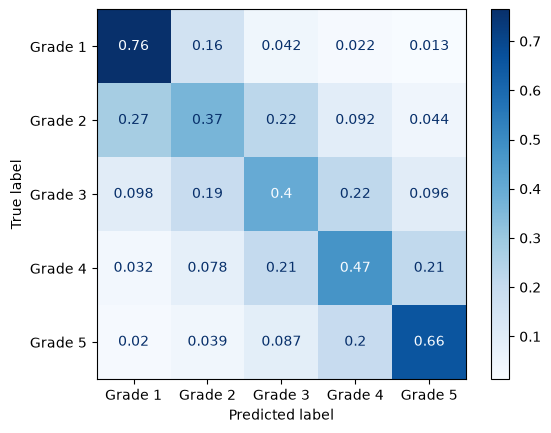

In [9]:
Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
best = search.best_estimator_.fit(Xtr, ytr)
pred = best.predict(Xva)
print("Macro F1 hold-out:", round(f1_score(yva, pred, average="macro"), 4))
print(classification_report(yva, pred, target_names=GRADES, digits=3))
ConfusionMatrixDisplay.from_predictions(yva, pred, display_labels=GRADES, normalize="true", cmap="Blues")
plt.savefig("reports/figures/confusion_matrix.png", dpi=150, bbox_inches="tight")

**Interpretasi hold-out:** Macro F1 hold-out 0,5134 (20% data latih penuh) lebih tinggi dari skor CV tuning 0,4924 karena model dilatih pada data yang jauh lebih banyak (sekitar 427 ribu baris dibanding subsampel 100 ribu dengan 2/3 untuk latih per fold). Per kelas, Grade 5 paling mudah (F1 0,705), sedangkan Grade 2 (0,349) dan Grade 3 (0,395) paling sulit. Pola ini wajar karena tingkat kerusakan berurutan, sehingga kelas tengah mirip dengan kedua tetangganya. Grade 1 punya recall tinggi (0,764) tetapi presisi lebih rendah (0,552). Macro recall (0,532) juga lebih besar dari macro precision (0,504). Ini efek `class_weight="balanced"`: model lebih berani menebak kelas minoritas demi Macro F1, dengan konsekuensi lebih banyak salah tebak ke kelas tersebut. Akurasi 0,544 bukan metrik utama pada kompetisi ini.

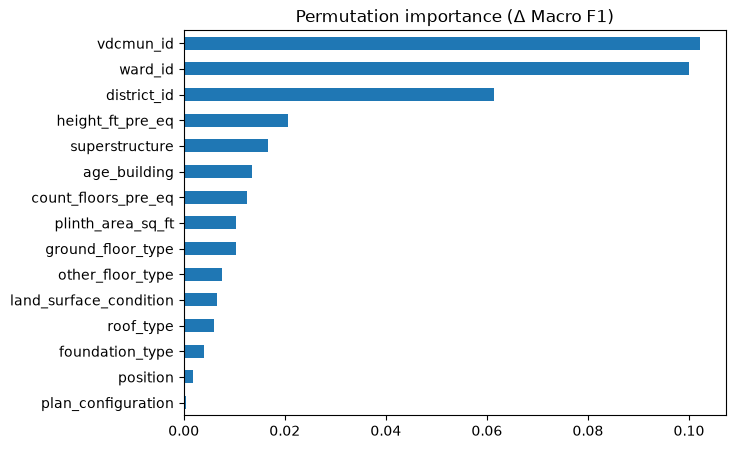

In [10]:
# Permutation importance pada fitur mentah (input pipeline) agar mudah diinterpretasi
idx = Xva.sample(20_000, random_state=SEED).index
pi = permutation_importance(best, Xva.loc[idx], yva.loc[idx], scoring="f1_macro",
                            n_repeats=3, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=Xva.columns).sort_values(ascending=False)
imp.head(15)[::-1].plot.barh(title="Permutation importance (Δ Macro F1)", figsize=(7, 5))
plt.tight_layout()
plt.savefig("reports/figures/feature_importance.png", dpi=150)

**Interpretasi feature importance** (permutation importance, penurunan Macro F1 pada 20 ribu baris hold-out, 3 pengulangan):

- **Lokasi dominan.** `vdcmun_id` (0,102), `ward_id` (0,100), dan `district_id` (0,061) jauh di atas fitur lain (di bawah 0,021). Ini konsisten dengan EDA: Grade 5 mencapai 81% di distrik 23 tetapi hanya 9% di distrik 31. Lokasi bekerja sebagai proksi intensitas guncangan, kondisi tanah, dan praktik membangun setempat. Semua ward di data test juga ada di data train (EDA), jadi informasi lokasi dapat dimanfaatkan penuh. Model ini belum tentu menggeneralisasi ke wilayah baru.
- **Karakteristik bangunan** berada di tingkat berikutnya: `height_ft_pre_eq` (0,021), `superstructure` (0,017), `age_building` (0,013), `count_floors_pre_eq` (0,013), `plinth_area_sq_ft` (0,010), dan `ground_floor_type` (0,010). Tinggi bangunan dan jenis struktur masuk akal secara teknik. Umur bangunan ikut berpengaruh, selaras dengan temuan EDA bahwa median umur naik dari 7 tahun (Grade 1) ke 20 tahun (Grade 5).
- **`roof_type` (0,006) dan `foundation_type` (0,004)** tampak kecil, padahal pada EDA atap RCC dan fondasi RC sangat tahan. Penyebab yang mungkin: fitur-fitur material saling berkorelasi (terutama dengan `superstructure`), sehingga permutation importance membagi pengaruhnya dan cenderung meremehkan fitur yang berkorelasi.
- **`position` dan `plan_configuration`** hampir tidak berpengaruh (di bawah 0,002). Pada EDA, `plan_configuration` memang punya 7 kategori yang masing-masing di bawah 1% data.

In [11]:
# Simpan hasil untuk laporan README
res_strategy.to_csv("reports/tables/compare_strategy.csv", index=False)
res_model.to_csv("reports/tables/compare_model.csv", index=False)
imp.head(15).to_csv("reports/tables/feature_importance.csv")